# Seminar 3: Exploratory Data Analysis & OLS Regression (Titanic Dataset)

## Objectives & Notebook Overview

This notebook provides a comprehensive Exploratory Data Analysis (EDA) of the Titanic passenger dataset (`titanic.csv`) along with Ordinary Least Squares (OLS) linear regressions to explore and visualise relationships:

1. **Data Ingestion & Integrity Audit**: Audit data types, missing values, duplicates, and initial summary statistics.
2. **Univariate Analysis**: Examine the distributions, spread, and outliers of individual features.
3. **Feature Engineering for EDA**: Derive family dynamics (`FamilySize`, `IsAlone`), title parsing (`Title_Grouped`), and fare transformations (`LogFare`).
4. **Bivariate & Multivariate Relationships**: Explore interactions and correlations with survival outcomes (`Survived`) and passenger socioeconomics.
5. **OLS Linear Regression Analysis (Bivariate Relationships with Survival)**:
   - Quantify and visualise the direction and strength of the linear relationship between `Survived` and every individual variable (`Sex`, `Pclass`, `Fare`, `LogFare`, `Age`, `FamilySize`, `SibSp`, `Parch`, `IsAlone`).
6. **OLS Linear Regression Analysis (Relationships Between Predictors)**:
   - Visualise linear relationships among socioeconomic and demographic variables (`Fare` vs. `Pclass`, `Age` vs. `Pclass`, `LogFare` vs. `Age`, `Fare` vs. `FamilySize`).
7. **Multiple Linear Regression (Controlled Relationships)**:
   - Compare univariate slopes against multivariate partial slopes to observe how relationships hold when other factors are controlled.

---
*Note: Linear regression is utilized throughout this notebook strictly as an exploratory and visual tool to quantify relationships, not as a predictive model.*

## 1. Environment & Library Setup

We load essential data manipulation (`pandas`, `numpy`), visualization (`matplotlib`, `seaborn`), and statistical modeling (`statsmodels`, `scipy`) libraries, and set global aesthetic defaults.

In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from scipy import stats

# Configure visualization styling
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
pd.set_option('display.float_format', lambda x: '%.4f' % x)

print("Environment configured and libraries loaded successfully.")

Environment configured and libraries loaded successfully.


## 2. Data Ingestion & Schema Audit

We ingest `titanic.csv` into a pandas DataFrame and inspect its dimensions, column types, and first 10 rows.

In [78]:
# Load Titanic dataset
df = pd.read_csv('titanic.csv')

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns\n")
display(df.head(10))

Dataset Dimensions: 891 rows, 12 columns



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0000,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0000,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0000,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0000,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0000,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0000,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0000,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0000,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0000,1,0,237736,30.0708,NaN,C


In [79]:
# Column schema and memory usage
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 3. Data Completeness & Integrity Checks

Before conducting descriptive or relational analysis, we perform data hygiene checks:
- Missing value profiling across all attributes (counts and percentages).
- Visualizing missingness magnitude.
- Duplicate record verification and unique value cardinality.

,Missing Count,Missing Pct (%),Data Type
Cabin,687,77.1044,str
Age,177,19.8653,float64
Embarked,2,0.2245,str


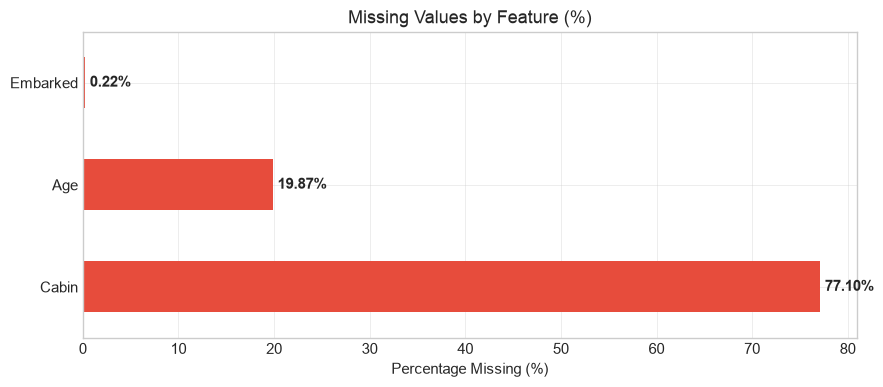

In [80]:
# Missing values audit
missing_count = df.isnull().sum()
missing_pct = (missing_count / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Pct (%)': missing_pct,
    'Data Type': df.dtypes
}).sort_values(by='Missing Count', ascending=False)

display(missing_df[missing_df['Missing Count'] > 0])

# Missingness horizontal bar visualization
fig, ax = plt.subplots(figsize=(9, 4))
missing_plot_data = missing_df[missing_df['Missing Count'] > 0]['Missing Pct (%)']
missing_plot_data.plot(kind='barh', color='#e74c3c', ax=ax)
ax.set_title('Missing Values by Feature (%)', fontsize=13)
ax.set_xlabel('Percentage Missing (%)')
for i, v in enumerate(missing_plot_data):
    ax.text(v + 0.5, i, f"{v:.2f}%", va='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [81]:
# Duplication and cardinality inspection
print(f"Total duplicate rows: {df.duplicated().sum()}")

cardinality_df = pd.DataFrame({
    'Unique Count': df.nunique(),
    'Sample Values': [df[col].dropna().unique()[:3].tolist() for col in df.columns]
})
display(cardinality_df)

Total duplicate rows: 0


,Unique Count,Sample Values
PassengerId,891,"[1, 2, 3]"
Survived,2,"[0, 1]"
Pclass,3,"[3, 1, 2]"
Name,891,"[Braund, Mr. Owen Harris, Cumings, Mrs. John B..."
Sex,2,"[male, female]"
Age,88,"[22.0, 38.0, 26.0]"
SibSp,7,"[1, 0, 3]"
Parch,7,"[0, 1, 2]"
Ticket,681,"[A/5 21171, PC 17599, STON/O2. 3101282]"
Fare,248,"[7.25, 71.2833, 7.925]"


## 4. Summary Statistics (Descriptive Analysis)

We compute comprehensive descriptive statistics:
- **Numerical Features**: Count, mean, standard deviation, percentiles (25%, 50%, 75%), min/max, interquartile range (IQR), and skewness.
- **Categorical Features**: Unique levels, mode (top occurring value), and frequency.

In [82]:
# Numerical summary statistics with skewness and IQR
num_summary = df.describe().T
num_summary['median'] = df.median(numeric_only=True)
num_summary['IQR'] = num_summary['75%'] - num_summary['25%']
num_summary['skewness'] = df.skew(numeric_only=True)

display(num_summary[['count', 'mean', 'std', 'min', '25%', 'median', '75%', 'max', 'IQR', 'skewness']])

,count,mean,std,min,25%,median,75%,max,IQR,skewness
PassengerId,891.0000,446.0000,257.3538,1.0000,223.5000,446.0000,668.5000,891.0000,445.0000,0.0000
Survived,891.0000,0.3838,0.4866,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,0.4785
Pclass,891.0000,2.3086,0.8361,1.0000,2.0000,3.0000,3.0000,3.0000,1.0000,-0.6305
Age,714.0000,29.6991,14.5265,0.4200,20.1250,28.0000,38.0000,80.0000,17.8750,0.3891
SibSp,891.0000,0.5230,1.1027,0.0000,0.0000,0.0000,1.0000,8.0000,1.0000,3.6954
Parch,891.0000,0.3816,0.8061,0.0000,0.0000,0.0000,0.0000,6.0000,0.0000,2.7491
Fare,891.0000,32.2042,49.6934,0.0000,7.9104,14.4542,31.0000,512.3292,23.0896,4.7873


In [83]:
# Categorical summary statistics
display(df.describe(include=['object', 'str']).T)

,count,unique,top,freq
Name,891,891,"Braund, Mr. Owen Harris",1
Sex,891,2,male,577
Ticket,891,681,347082,7
Cabin,204,147,G6,4
Embarked,889,3,S,644


## 5. Univariate Feature Distributions

We evaluate the distribution and spread of individual variables:
- **Survival Outcome**: Class balance and survival proportions.
- **Continuous Features**: Age and ticket Fare (histograms, KDE curves, and outlier boxplots).
- **Categorical & Discrete Features**: Passenger class (`Pclass`), `Sex`, port of embarkation (`Embarked`), and traveling family counts (`SibSp`, `Parch`).

/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_4101/865214567.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Perished (0)', 'Survived (1)'])


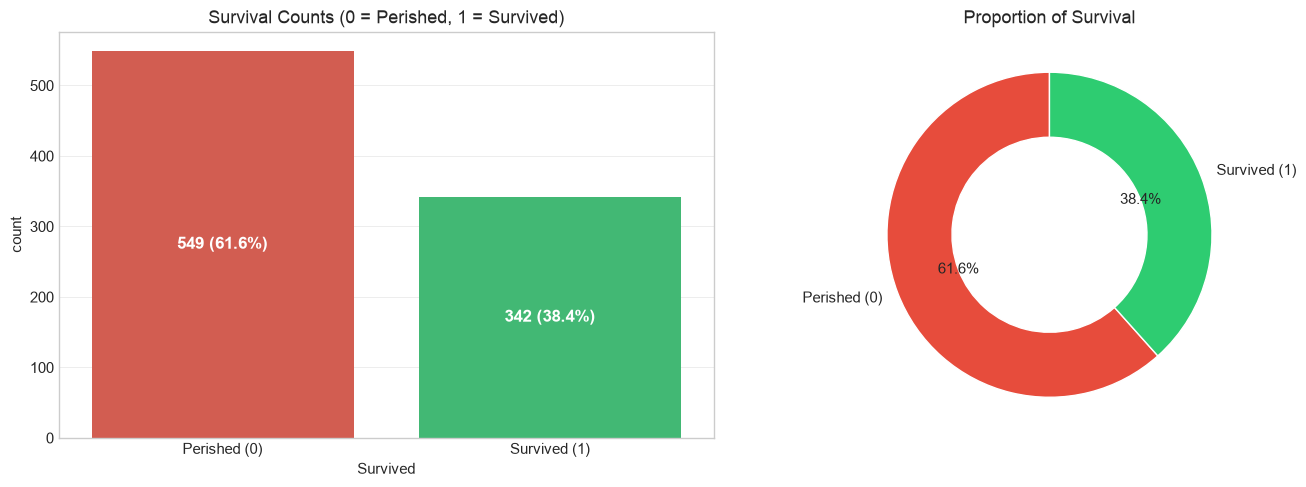

In [84]:
# Target variable distribution: Survived
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Survival counts bar plot
sns.countplot(x='Survived', data=df, palette=['#e74c3c', '#2ecc71'], ax=axes[0], hue='Survived', legend=False)
axes[0].set_title('Survival Counts (0 = Perished, 1 = Survived)', fontsize=13)
axes[0].set_xticklabels(['Perished (0)', 'Survived (1)'])
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height())} ({p.get_height()/len(df)*100:.1f}%)", 
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=12, color='white', weight='bold')

# Survival proportion donut chart
survived_counts = df['Survived'].value_counts()
axes[1].pie(survived_counts, labels=['Perished (0)', 'Survived (1)'], autopct='%1.1f%%',
            startangle=90, colors=['#e74c3c', '#2ecc71'], wedgeprops=dict(width=0.4, edgecolor='w'))
axes[1].set_title('Proportion of Survival', fontsize=13)

plt.tight_layout()
plt.show()

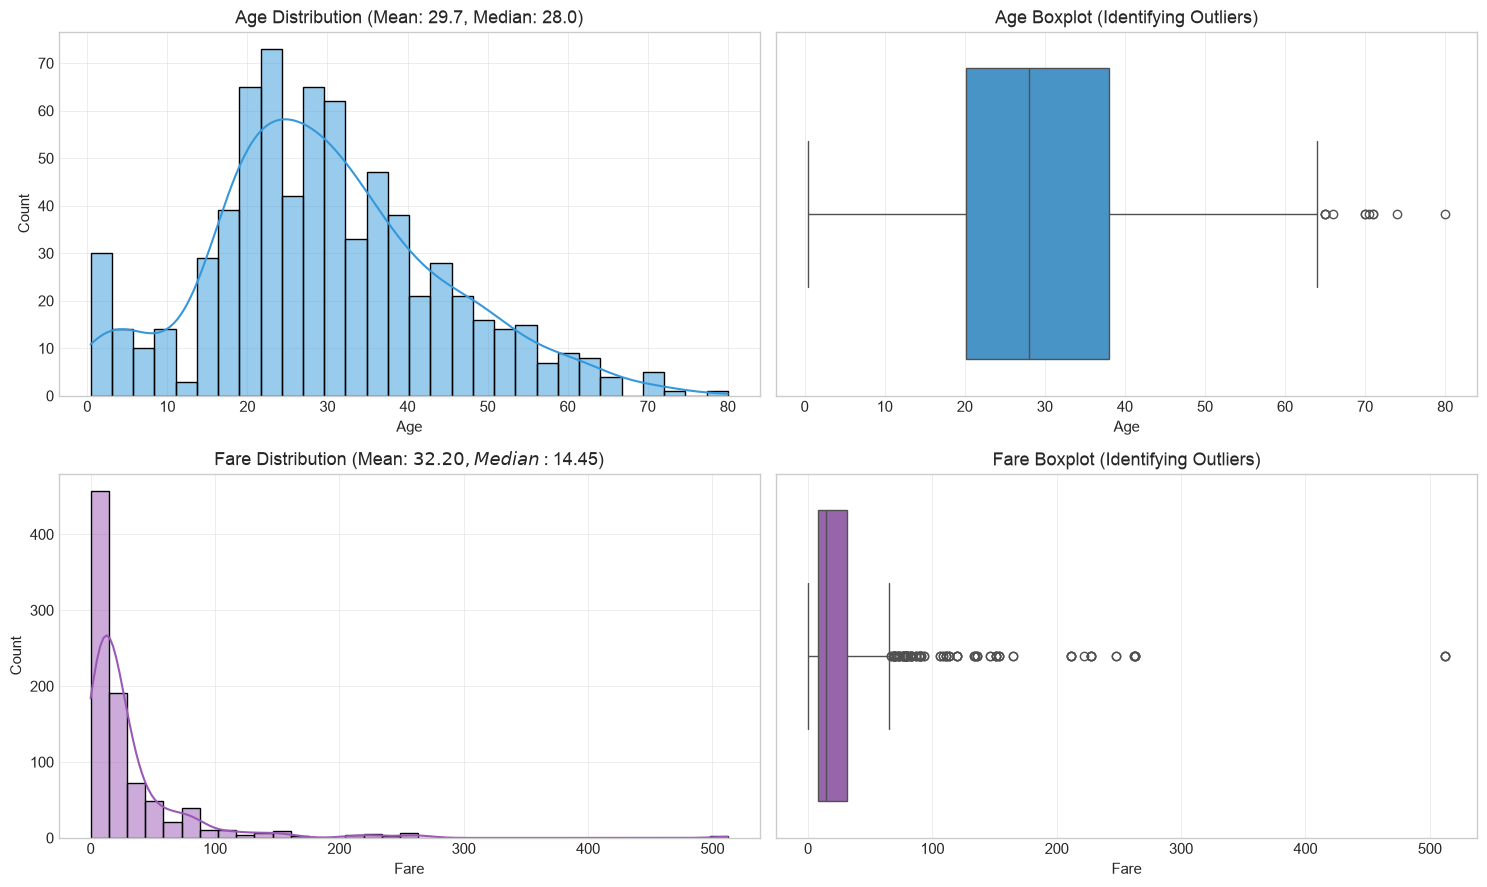

In [85]:
# Continuous numerical distributions: Age and Fare
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# Age Histogram & KDE
sns.histplot(df['Age'].dropna(), kde=True, ax=axes[0, 0], color='#3498db', bins=30)
axes[0, 0].set_title(f"Age Distribution (Mean: {df['Age'].mean():.1f}, Median: {df['Age'].median():.1f})")

# Age Boxplot
sns.boxplot(x=df['Age'], ax=axes[0, 1], color='#3498db')
axes[0, 1].set_title('Age Boxplot (Identifying Outliers)')

# Fare Histogram & KDE
sns.histplot(df['Fare'], kde=True, ax=axes[1, 0], color='#9b59b6', bins=35)
axes[1, 0].set_title(f"Fare Distribution (Mean: ${df['Fare'].mean():.2f}, Median: ${df['Fare'].median():.2f})")

# Fare Boxplot
sns.boxplot(x=df['Fare'], ax=axes[1, 1], color='#9b59b6')
axes[1, 1].set_title('Fare Boxplot (Identifying Outliers)')

plt.tight_layout()
plt.show()

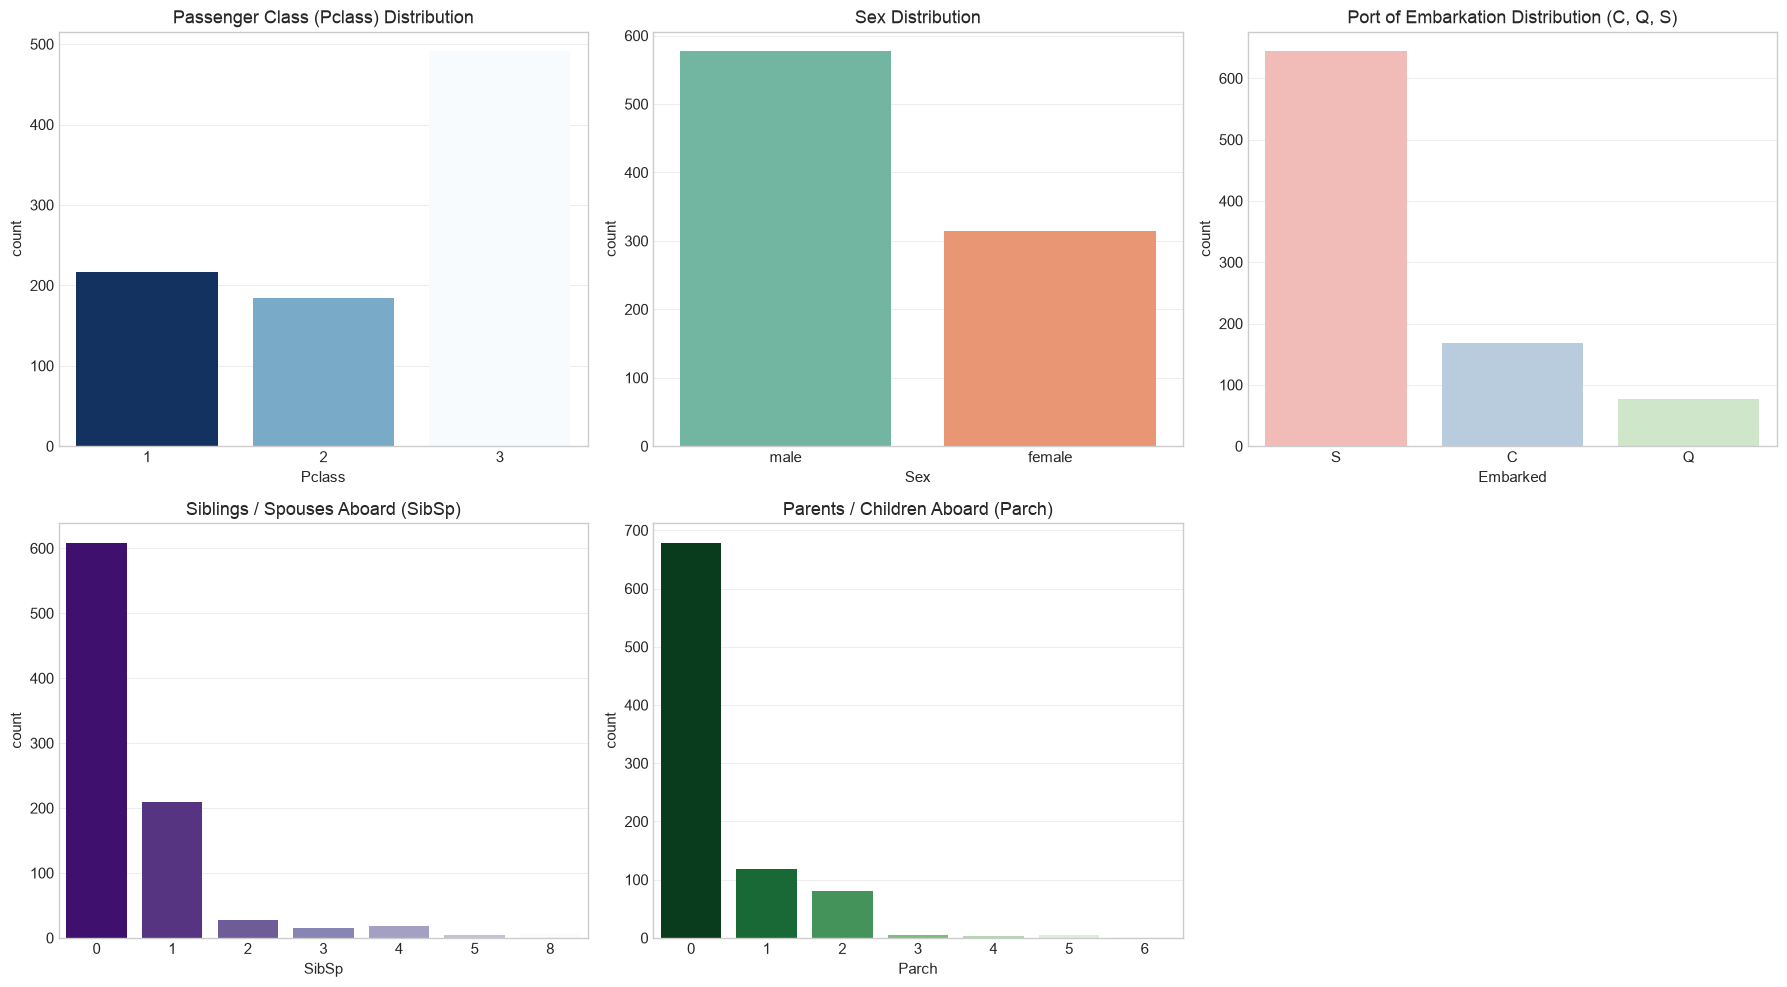

In [86]:
# Categorical and discrete feature counts
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

sns.countplot(x='Pclass', data=df, palette='Blues_r', ax=axes[0, 0], hue='Pclass', legend=False)
axes[0, 0].set_title('Passenger Class (Pclass) Distribution')

sns.countplot(x='Sex', data=df, palette='Set2', ax=axes[0, 1], hue='Sex', legend=False)
axes[0, 1].set_title('Sex Distribution')

sns.countplot(x='Embarked', data=df, palette='Pastel1', ax=axes[0, 2], hue='Embarked', legend=False)
axes[0, 2].set_title('Port of Embarkation Distribution (C, Q, S)')

sns.countplot(x='SibSp', data=df, palette='Purples_r', ax=axes[1, 0], hue='SibSp', legend=False)
axes[1, 0].set_title('Siblings / Spouses Aboard (SibSp)')

sns.countplot(x='Parch', data=df, palette='Greens_r', ax=axes[1, 1], hue='Parch', legend=False)
axes[1, 1].set_title('Parents / Children Aboard (Parch)')

axes[1, 2].axis('off')
plt.tight_layout()
plt.show()

## 6. Feature Engineering for In-Depth Exploration

We construct derived variables to support relationship and regression analyses:

- **`IsMale`**: Binary indicator (`1` for male, `0` for female) for direct linear slope calculation.
- **`FamilySize`**: Total traveling group size (`SibSp + Parch + 1`).
- **`IsAlone`**: Indicator variable for solo travelers (`FamilySize == 1`).
- **`Title_Grouped`**: Honorific extracted from passenger `Name` (e.g., `Mr`, `Miss`, `Mrs`, `Master`, `Rare`).
- **`Deck`**: Deck level parsed from the first character of `Cabin`.
- **`LogFare`**: Natural logarithm transformation `log(Fare + 1)` to stabilize severe positive skewness.
- **`AgeGroup`**: Binned age brackets (Child, Teen, Young Adult, Adult, Senior) for tabular cross-tabulations.

In [87]:
df_feat = df.copy()

# 1. Binary indicator for Sex (1 = Male, 0 = Female)
df_feat['IsMale'] = (df_feat['Sex'] == 'male').astype(int)

# 2. Family Size & Solo Status
df_feat['FamilySize'] = df_feat['SibSp'] + df_feat['Parch'] + 1
df_feat['IsAlone'] = (df_feat['FamilySize'] == 1).astype(int)

# 3. Extract Title from Name
df_feat['Title'] = df_feat['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
common_titles = ['Mr', 'Miss', 'Mrs', 'Master']
df_feat['Title_Grouped'] = df_feat['Title'].apply(lambda x: x if x in common_titles else 'Rare')

# 4. Cabin Deck
df_feat['Deck'] = df_feat['Cabin'].str[0].fillna('Unknown')

# 5. Log Transformation of Fare
df_feat['LogFare'] = np.log1p(df_feat['Fare'])

# 6. Age Binning for tabular comparisons
df_feat['AgeGroup'] = pd.cut(df_feat['Age'], bins=[0, 12, 18, 35, 60, 100], 
                             labels=['Child (0-12)', 'Teen (13-18)', 'Young Adult (19-35)', 'Adult (36-60)', 'Senior (61+)'])

display(df_feat[['PassengerId', 'Name', 'IsMale', 'Title_Grouped', 'FamilySize', 'IsAlone', 'Deck', 'LogFare', 'AgeGroup']].head(8))

,PassengerId,Name,IsMale,Title_Grouped,FamilySize,IsAlone,Deck,LogFare,AgeGroup
0,1,"Braund, Mr. Owen Harris",1,Mr,2,0,Unknown,2.1102,Young Adult (19-35)
1,2,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,Mrs,2,0,C,4.2806,Adult (36-60)
2,3,"Heikkinen, Miss. Laina",0,Miss,1,1,Unknown,2.1889,Young Adult (19-35)
3,4,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,Mrs,2,0,C,3.9908,Young Adult (19-35)
4,5,"Allen, Mr. William Henry",1,Mr,1,1,Unknown,2.2028,Young Adult (19-35)
5,6,"Moran, Mr. James",1,Mr,1,1,Unknown,2.2469,NaN
6,7,"McCarthy, Mr. Timothy J",1,Mr,1,1,E,3.9677,Adult (36-60)
7,8,"Palsson, Master. Gosta Leonard",1,Master,5,0,Unknown,3.0944,Child (0-12)


## 7. Bivariate & Multivariate Relationship Analysis

We investigate associations between passenger characteristics and survival:
- Survival rates across demographic categories (`Sex`, `Pclass`, `Embarked`, `Title`).
- Cross-tabulation matrices detailing survival percentages.
- Interaction effects between passenger class and gender (`Pclass` vs. `Sex`).
- Relationship between family size and survival probability.
- Age and fare density profiles by survival status.
- Linear (Pearson) and monotonic rank (Spearman) correlation matrices.
- Pairwise multivariate feature distributions.

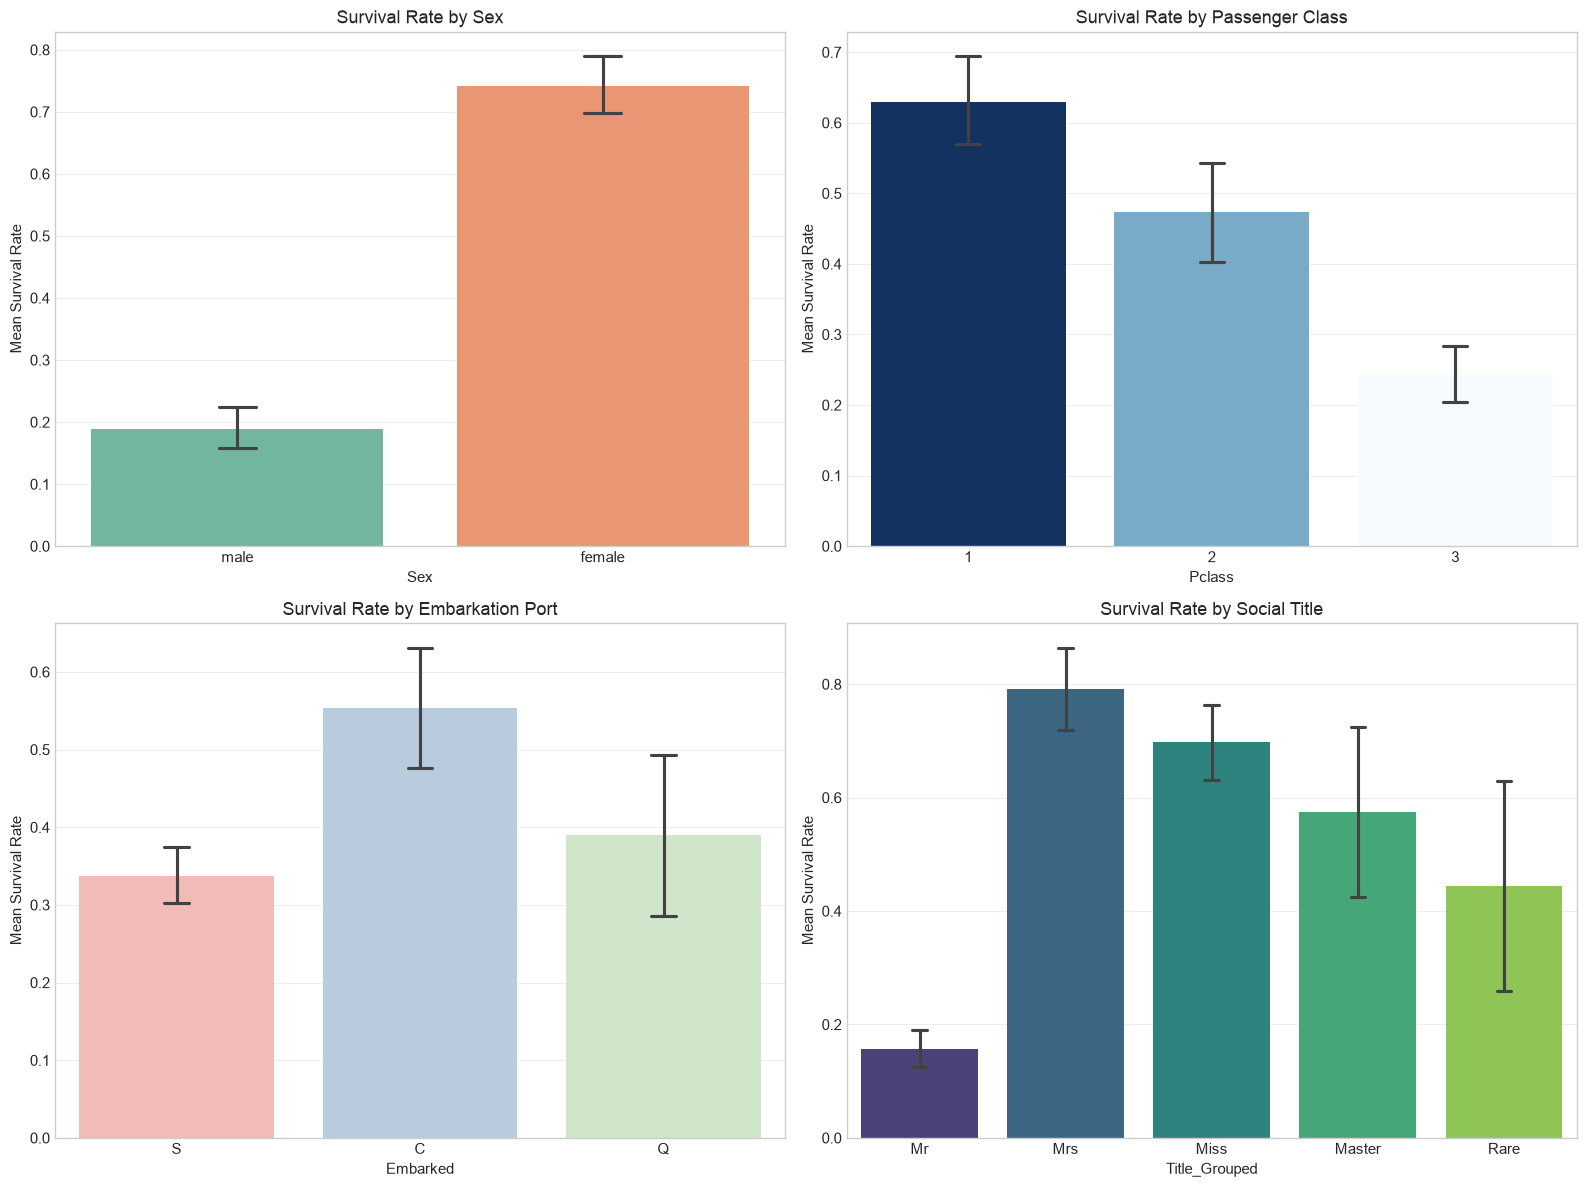

In [88]:
# Categorical predictors vs. Survival Rate
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Sex vs Survived
sns.barplot(x='Sex', y='Survived', data=df_feat, palette='Set2', ax=axes[0, 0], capsize=0.1, hue='Sex', legend=False)
axes[0, 0].set_title('Survival Rate by Sex')
axes[0, 0].set_ylabel('Mean Survival Rate')

# Pclass vs Survived
sns.barplot(x='Pclass', y='Survived', data=df_feat, palette='Blues_r', ax=axes[0, 1], capsize=0.1, hue='Pclass', legend=False)
axes[0, 1].set_title('Survival Rate by Passenger Class')
axes[0, 1].set_ylabel('Mean Survival Rate')

# Embarked vs Survived
sns.barplot(x='Embarked', y='Survived', data=df_feat, palette='Pastel1', ax=axes[1, 0], capsize=0.1, hue='Embarked', legend=False)
axes[1, 0].set_title('Survival Rate by Embarkation Port')
axes[1, 0].set_ylabel('Mean Survival Rate')

# Title Grouped vs Survived
sns.barplot(x='Title_Grouped', y='Survived', data=df_feat, palette='viridis', ax=axes[1, 1], capsize=0.1, hue='Title_Grouped', legend=False)
axes[1, 1].set_title('Survival Rate by Social Title')
axes[1, 1].set_ylabel('Mean Survival Rate')

plt.tight_layout()
plt.show()

In [89]:
# Demographic interaction cross-tabulations
print("Survival Percentage by Sex:")
display(pd.crosstab(df_feat['Sex'], df_feat['Survived'], normalize='index', margins=True).round(4) * 100)

print("\nSurvival Percentage by Class and Sex:")
display(pd.crosstab([df_feat['Pclass'], df_feat['Sex']], df_feat['Survived'], normalize='index', margins=True).round(4) * 100)

print("\nSurvival Percentage by Age Group:")
display(pd.crosstab(df_feat['AgeGroup'], df_feat['Survived'], normalize='index', margins=True).round(4) * 100)

Survival Percentage by Sex:


Survived,0,1
Sex,,
female,25.8000,74.2000
male,81.1100,18.8900
All,61.6200,38.3800



Survival Percentage by Class and Sex:


Survived            0       1
Pclass Sex                   
1      female  3.1900 96.8100
       male   63.1100 36.8900
2      female  7.8900 92.1100
       male   84.2600 15.7400
3      female 50.0000 50.0000
       male   86.4600 13.5400
All           61.6200 38.3800


Survival Percentage by Age Group:


Survived,0,1
AgeGroup,,
Child (0-12),42.0300,57.9700
Teen (13-18),57.1400,42.8600
Young Adult (19-35),61.7300,38.2700
Adult (36-60),60.0000,40.0000
Senior (61+),77.2700,22.7300
All,59.3800,40.6200


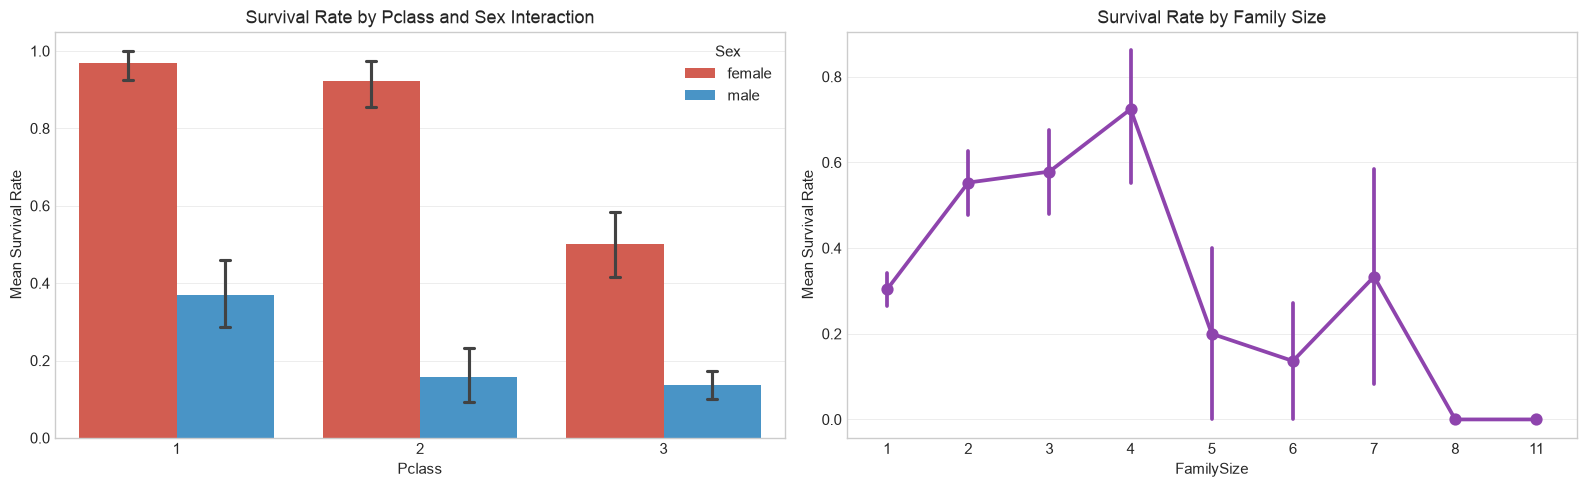

In [90]:
# Multi-dimensional interactions: Class x Sex, and Family Dynamics
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Pclass x Sex interaction
sns.barplot(x='Pclass', y='Survived', hue='Sex', data=df_feat, palette={'male': '#3498db', 'female': '#e74c3c'}, ax=axes[0], capsize=0.08)
axes[0].set_title('Survival Rate by Pclass and Sex Interaction')
axes[0].set_ylabel('Mean Survival Rate')

# Family Size vs Survival Rate
sns.pointplot(x='FamilySize', y='Survived', data=df_feat, color='#8e44ad', ax=axes[1], markers='o')
axes[1].set_title('Survival Rate by Family Size')
axes[1].set_ylabel('Mean Survival Rate')

plt.tight_layout()
plt.show()

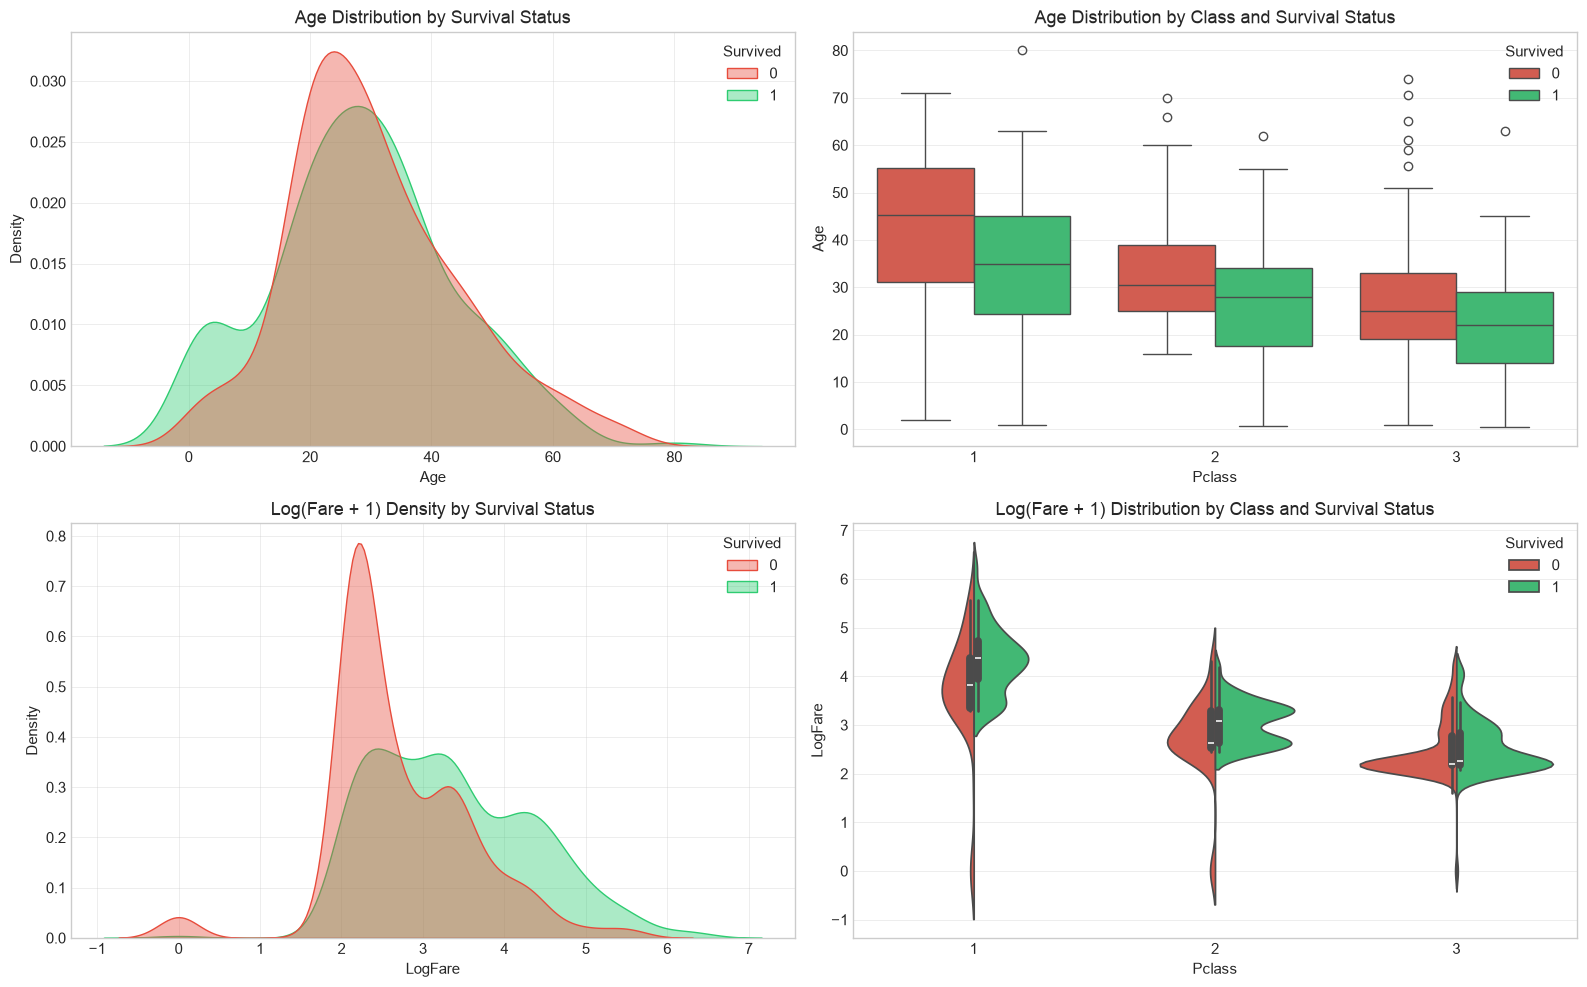

In [91]:
# Continuous predictors vs. Survival
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Age KDE by Survival
sns.kdeplot(data=df_feat, x='Age', hue='Survived', common_norm=False, fill=True, alpha=0.4, palette=['#e74c3c', '#2ecc71'], ax=axes[0, 0])
axes[0, 0].set_title('Age Distribution by Survival Status')

# Age Boxplot by Class and Survival
sns.boxplot(x='Pclass', y='Age', hue='Survived', data=df_feat, palette=['#e74c3c', '#2ecc71'], ax=axes[0, 1])
axes[0, 1].set_title('Age Distribution by Class and Survival Status')

# LogFare KDE by Survival
sns.kdeplot(data=df_feat, x='LogFare', hue='Survived', common_norm=False, fill=True, alpha=0.4, palette=['#e74c3c', '#2ecc71'], ax=axes[1, 0])
axes[1, 0].set_title('Log(Fare + 1) Density by Survival Status')

# LogFare Violin plot by Class and Survival
sns.violinplot(x='Pclass', y='LogFare', hue='Survived', data=df_feat, split=True, palette=['#e74c3c', '#2ecc71'], ax=axes[1, 1])
axes[1, 1].set_title('Log(Fare + 1) Distribution by Class and Survival Status')

plt.tight_layout()
plt.show()

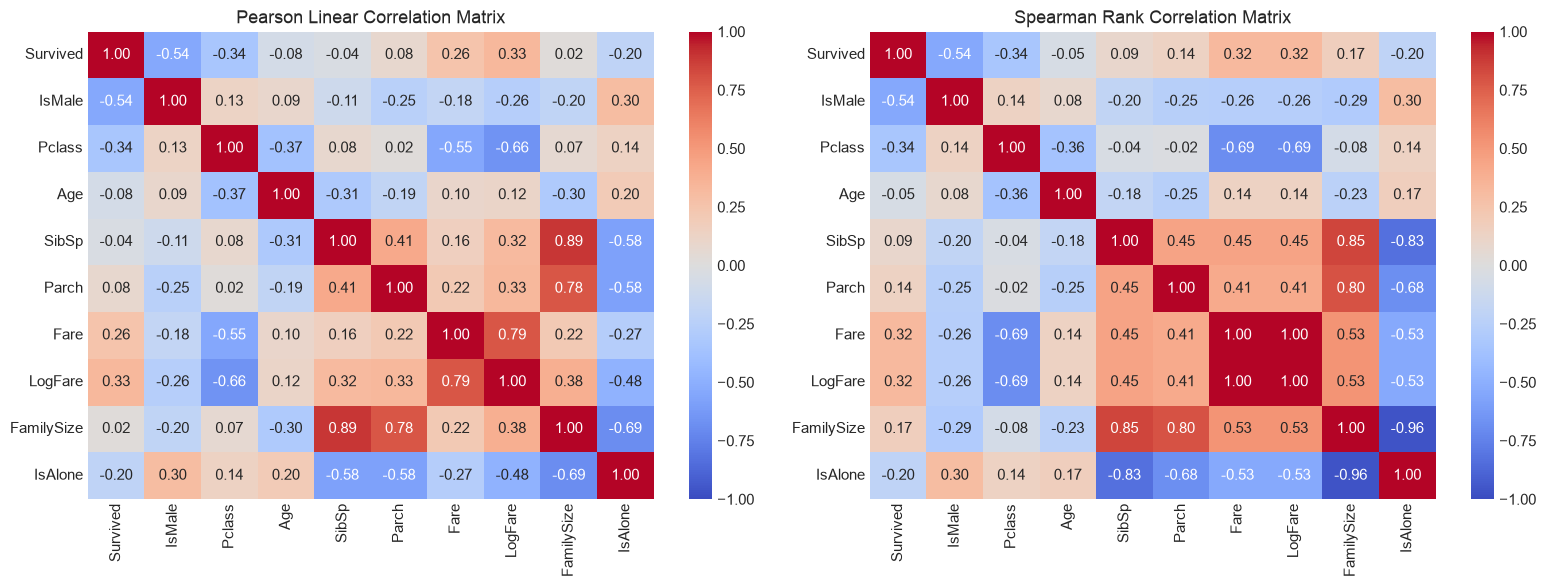

In [92]:
# Correlation Matrices (Pearson vs Spearman)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

corr_cols = ['Survived', 'IsMale', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'LogFare', 'FamilySize', 'IsAlone']

# Pearson correlation (linear)
sns.heatmap(df_feat[corr_cols].corr(method='pearson'), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Pearson Linear Correlation Matrix')

# Spearman rank correlation (monotonic)
sns.heatmap(df_feat[corr_cols].corr(method='spearman'), annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman Rank Correlation Matrix')

plt.tight_layout()
plt.show()

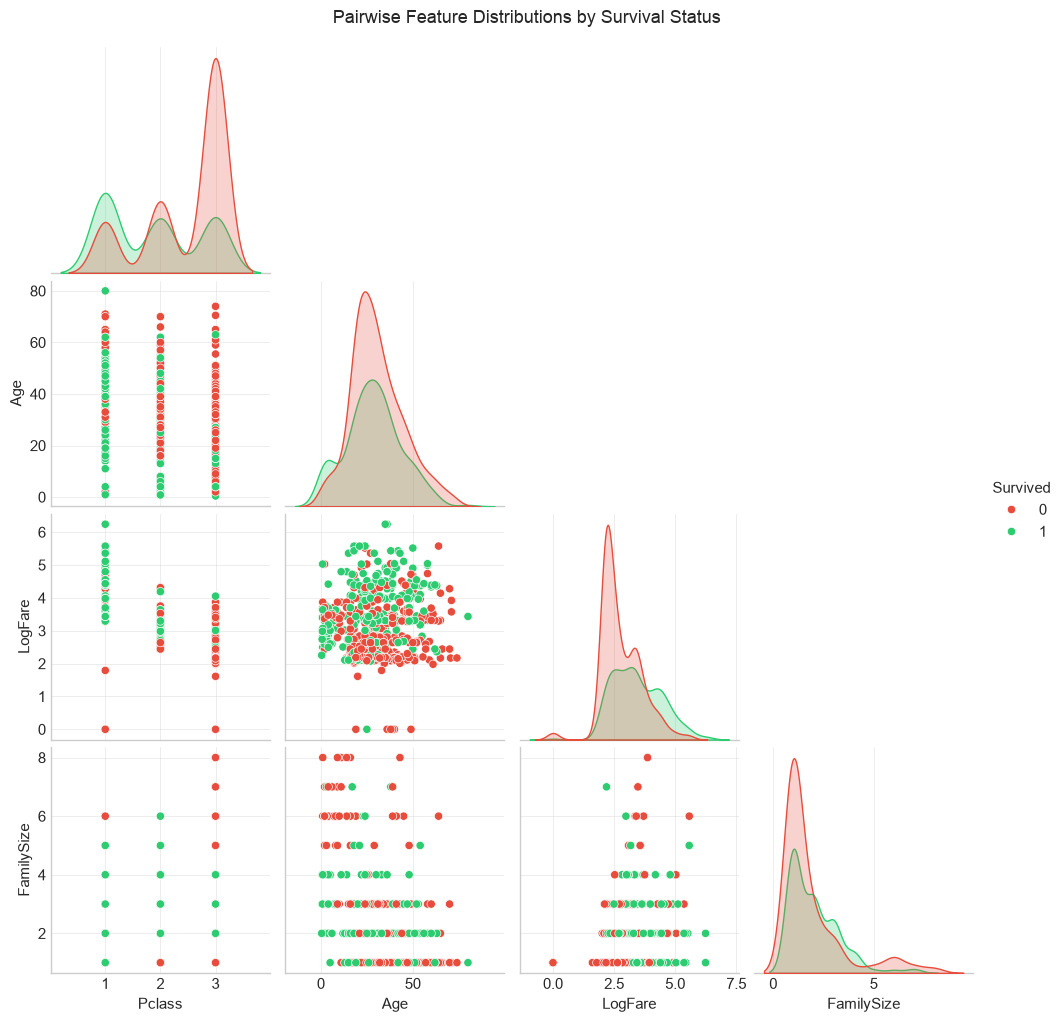

In [93]:
# Pairwise scatter & distribution grid
pair_vars = ['Survived', 'Pclass', 'Age', 'LogFare', 'FamilySize']
grid = sns.pairplot(df_feat[pair_vars].dropna(), hue='Survived', palette=['#e74c3c', '#2ecc71'], corner=True, diag_kind='kde')
grid.fig.suptitle('Pairwise Feature Distributions by Survival Status', y=1.02)
plt.show()

## 8. Linear Regression: Visualising Bivariate Relationships Between Survival and Every Variable

Here we use Ordinary Least Squares (OLS) linear regression not as a predictive model, but as an exploratory tool to quantify and visualise the directional relationship between passenger survival (`Survived`) and each individual variable:

$$\text{Survived} = \beta_0 + \beta_1 X + \varepsilon$$

- **Slope (Beta_1)**: The change in survival probability associated with a one-unit increase in variable $X$.
- **R-squared**: The proportion of variance in survival explained by that single feature alone.
- **p-value**: Statistical significance of the linear slope.

In [94]:
# Fit simple bivariate OLS linear regressions for every feature vs. Survived
bivariate_features = [
    ('Sex (IsMale: 0=F, 1=M)', 'IsMale'),
    ('Ticket Class (Pclass: 1, 2, 3)', 'Pclass'),
    ('Log(Fare + 1)', 'LogFare'),
    ('Ticket Fare ($)', 'Fare'),
    ('Age (Years)', 'Age'),
    ('Family Size (SibSp+Parch+1)', 'FamilySize'),
    ('Siblings / Spouses (SibSp)', 'SibSp'),
    ('Parents / Children (Parch)', 'Parch'),
    ('Solo Traveler (IsAlone: 0/1)', 'IsAlone')
]

biv_records = []
biv_models = {}

for label, col in bivariate_features:
    subset = df_feat[['Survived', col]].dropna()
    mod = smf.ols(f'Survived ~ {col}', data=subset).fit()
    biv_models[col] = mod
    
    slope = mod.params[col]
    intercept = mod.params['Intercept']
    se = mod.bse[col]
    pval = mod.pvalues[col]
    ci = mod.conf_int().loc[col]
    r2 = mod.rsquared
    
    if pval < 0.001:
        sig = '*** (p < 0.001)'
    elif pval < 0.01:
        sig = '** (p < 0.01)'
    elif pval < 0.05:
        sig = '* (p < 0.05)'
    else:
        sig = 'Not Significant'
        
    direction = 'Negative (-)' if slope < 0 else 'Positive (+)'
    
    biv_records.append({
        'Predictor Feature': label,
        'Intercept (Beta_0)': intercept,
        'Slope (Beta_1)': slope,
        'Std Error': se,
        'p-value': pval,
        'Significance': sig,
        '95% Confidence Interval': f"[{ci[0]:.4f}, {ci[1]:.4f}]",
        'R-squared': r2,
        'Direction': direction,
        'Observations (N)': int(mod.nobs)
    })

biv_summary_df = pd.DataFrame(biv_records)
print("=== BIVARIATE LINEAR REGRESSION SUMMARY: RELATIONSHIP WITH SURVIVAL ===")
display(biv_summary_df[['Predictor Feature', 'Slope (Beta_1)', 'Direction', 'Significance', 'R-squared', '95% Confidence Interval', 'Observations (N)']])

=== BIVARIATE LINEAR REGRESSION SUMMARY: RELATIONSHIP WITH SURVIVAL ===


,Predictor Feature,Slope (Beta_1),Direction,Significance,R-squared,95% Confidence Interval,Observations (N)
0,"Sex (IsMale: 0=F, 1=M)",-0.5531,Negative (-),*** (p < 0.001),0.2952,"[-0.6094, -0.4969]",891
1,"Ticket Class (Pclass: 1, 2, 3)",-0.1970,Negative (-),*** (p < 0.001),0.1146,"[-0.2330, -0.1609]",891
2,Log(Fare + 1),0.1656,Positive (+),*** (p < 0.001),0.1088,"[0.1344, 0.1968]",891
3,Ticket Fare ($),0.0025,Positive (+),*** (p < 0.001),0.0662,"[0.0019, 0.0031]",891
4,Age (Years),-0.0026,Negative (-),* (p < 0.05),0.0060,"[-0.0051, -0.0001]",714
5,Family Size (SibSp+Parch+1),0.0050,Positive (+),Not Significant,0.0003,"[-0.0148, 0.0249]",891
6,Siblings / Spouses (SibSp),-0.0156,Negative (-),Not Significant,0.0012,"[-0.0446, 0.0134]",891
7,Parents / Children (Parch),0.0493,Positive (+),* (p < 0.05),0.0067,"[0.0097, 0.0889]",891
8,Solo Traveler (IsAlone: 0/1),-0.2021,Negative (-),*** (p < 0.001),0.0414,"[-0.2662, -0.1381]",891


/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_4101/702434990.py:44: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) Arial.
  plt.tight_layout()
/opt/miniconda3/envs/datascience-genai-submissions/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


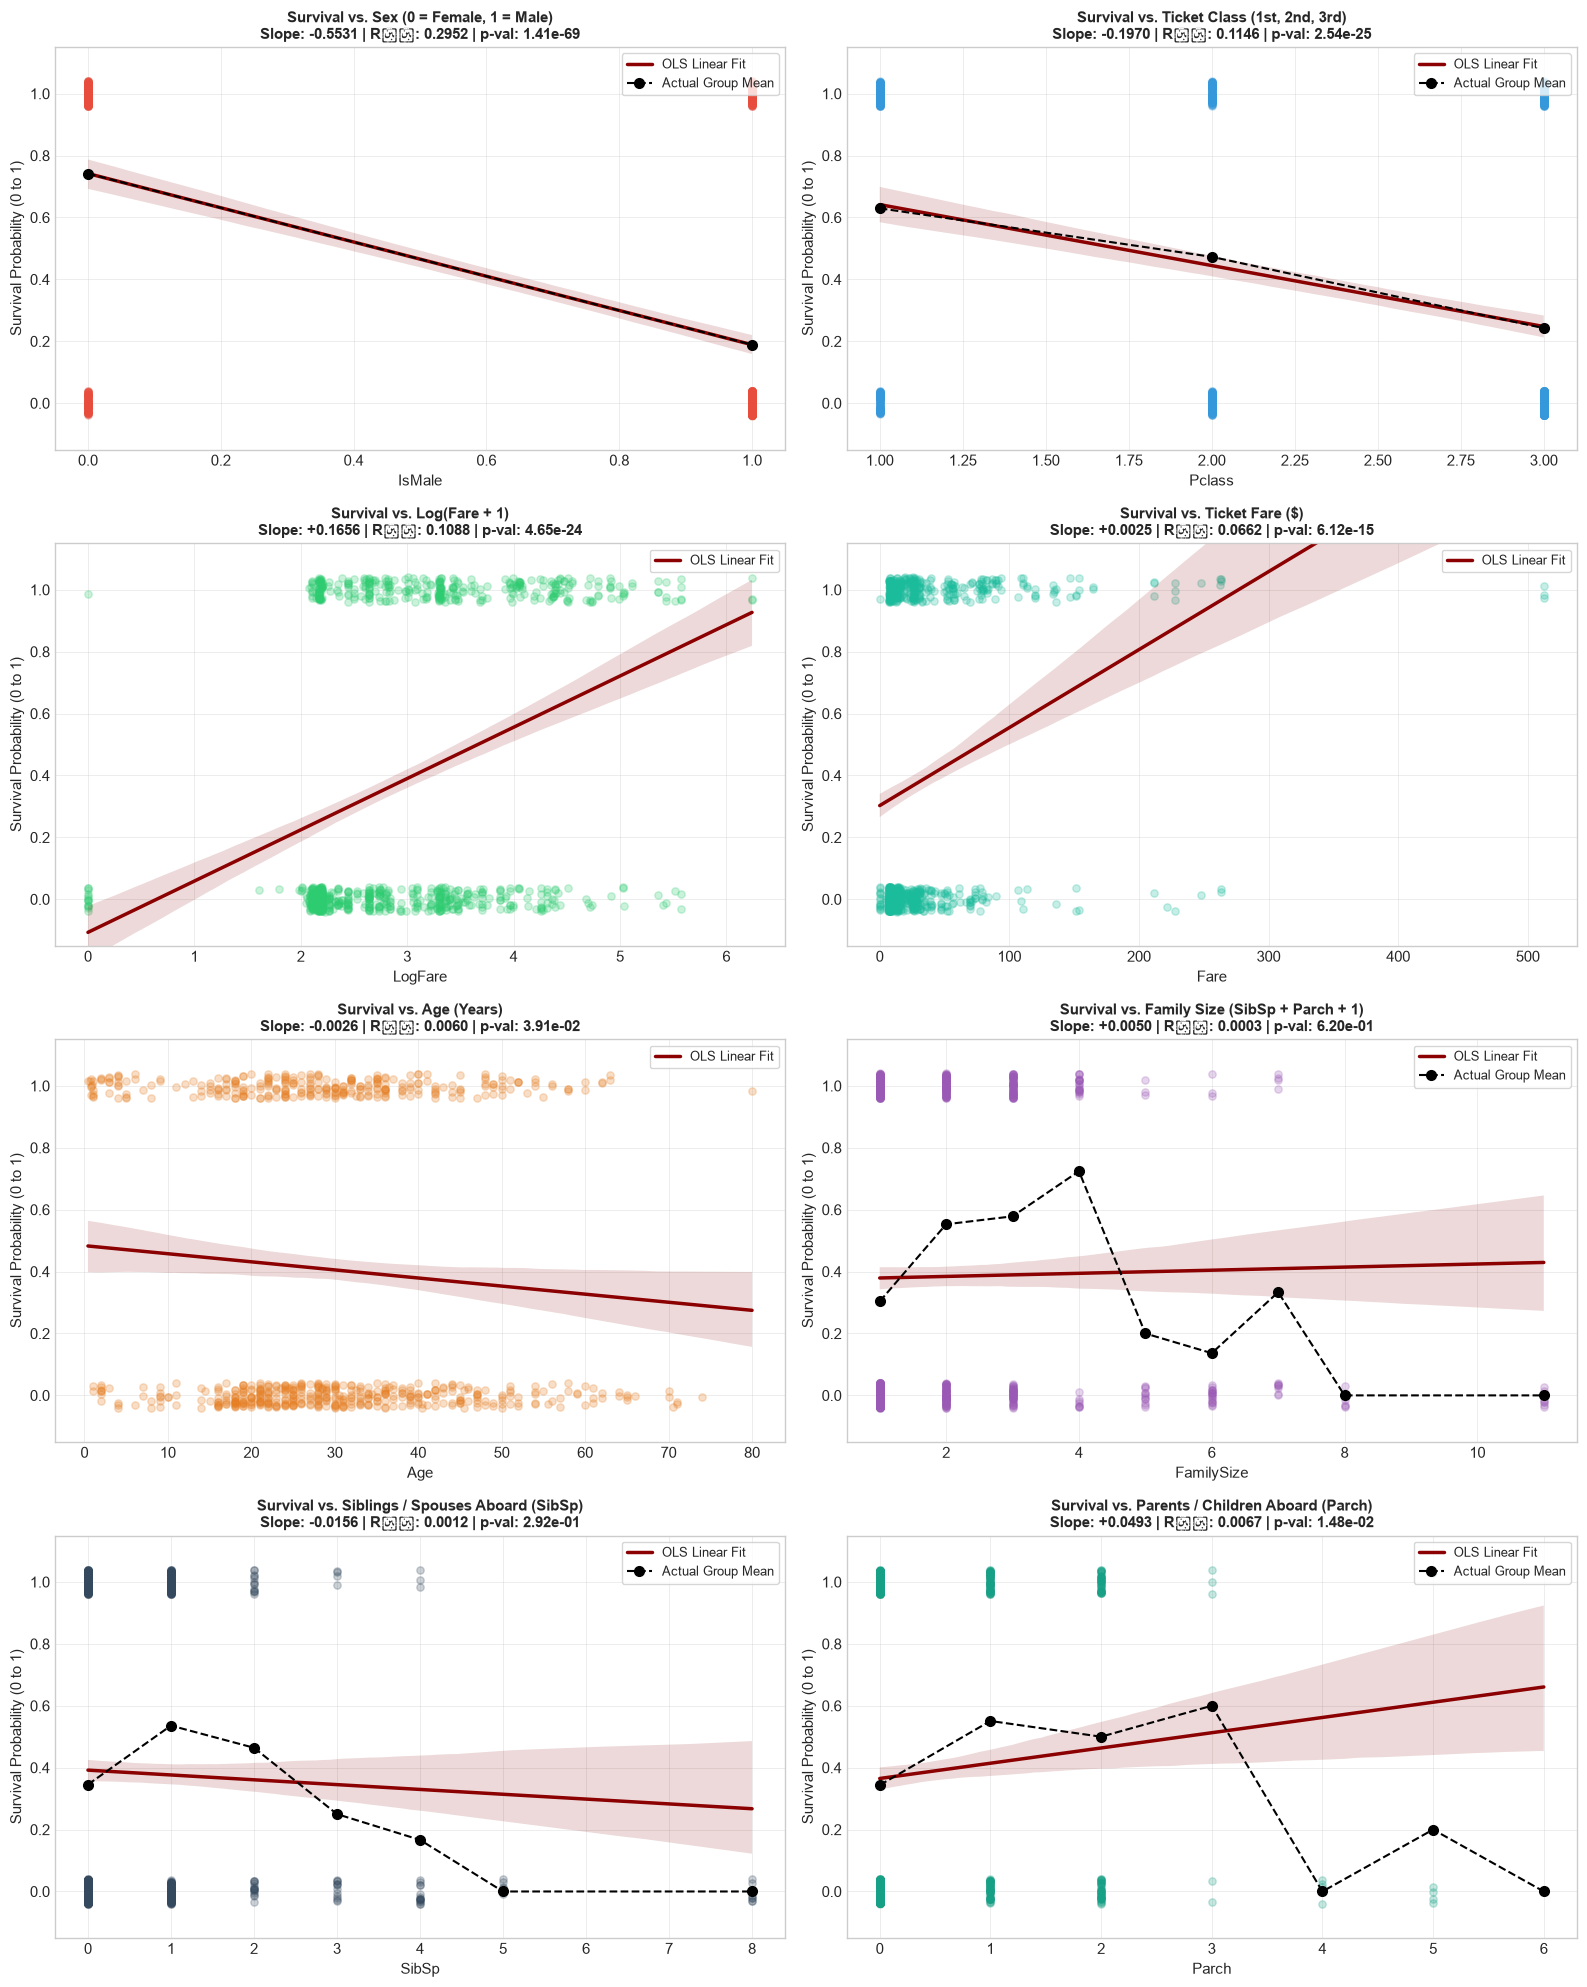

In [95]:
# Visualise Linear Regression Relationships with Survived (Grid of Regression Plots)
fig, axes = plt.subplots(4, 2, figsize=(16, 20))
axes = axes.flatten()

plot_configs = [
    ('IsMale', 'Sex (0 = Female, 1 = Male)', '#e74c3c'),
    ('Pclass', 'Ticket Class (1st, 2nd, 3rd)', '#3498db'),
    ('LogFare', 'Log(Fare + 1)', '#2ecc71'),
    ('Fare', 'Ticket Fare ($)', '#1abc9c'),
    ('Age', 'Age (Years)', '#e67e22'),
    ('FamilySize', 'Family Size (SibSp + Parch + 1)', '#9b59b6'),
    ('SibSp', 'Siblings / Spouses Aboard (SibSp)', '#34495e'),
    ('Parch', 'Parents / Children Aboard (Parch)', '#16a085')
]

for idx, (col, title, color) in enumerate(plot_configs):
    ax = axes[idx]
    
    # Scatter with jitter on y to visualize binary 0/1 density, overlaid with OLS regression line
    sns.regplot(
        x=col, y='Survived', data=df_feat, ax=ax,
        color=color,
        scatter_kws={'alpha': 0.25, 's': 28},
        line_kws={'color': 'darkred', 'linewidth': 2.5, 'label': 'OLS Linear Fit'},
        y_jitter=0.04
    )
    
    # Overlay binned empirical group means to visually compare linear fit vs actual mean survival
    if df_feat[col].nunique() <= 10:
        group_means = df_feat.groupby(col)['Survived'].mean()
        ax.plot(group_means.index, group_means.values, 'o--', color='black', markersize=7, linewidth=1.5, label='Actual Group Mean')
    
    # Retrieve slope and R-squared for annotation
    mod = biv_models[col]
    slope_val = mod.params[col]
    r2_val = mod.rsquared
    pval_val = mod.pvalues[col]
    
    ax.set_title(f"Survival vs. {title}\nSlope: {slope_val:+.4f} | R﷿﷿: {r2_val:.4f} | p-val: {pval_val:.2e}", fontsize=11, fontweight='bold')
    ax.set_ylabel('Survival Probability (0 to 1)')
    ax.set_ylim(-0.15, 1.15)
    ax.legend(loc='upper right', frameon=True, fontsize=9)

plt.tight_layout()
plt.show()

## 9. Linear Regression: Visualising Relationships Between Predictor Variables

Beyond survival, linear regression is an effective way to explore how demographic and socioeconomic variables relate to each other:
1. **Ticket Fare vs. Passenger Class (`LogFare ~ Pclass`)**: Quantifying the steep pricing gradient between ticket classes.
2. **Passenger Age vs. Passenger Class (`Age ~ Pclass`)**: Quantifying the demographic age differences across passenger classes.
3. **Ticket Fare vs. Passenger Age (`LogFare ~ Age`)**: Observing whether older passengers purchased higher-tier tickets.
4. **Ticket Fare vs. Family Size (`Fare ~ FamilySize`)**: Examining how total ticket expenditure scales with travelling group size.

In [96]:
# Fit OLS linear regressions between pairs of predictor variables
inter_pairs = [
    ('LogFare ~ Pclass', 'LogFare', 'Pclass', 'Ticket Class vs. Log(Fare + 1)'),
    ('Age ~ Pclass', 'Age', 'Pclass', 'Ticket Class vs. Age'),
    ('LogFare ~ Age', 'LogFare', 'Age', 'Age vs. Log(Fare + 1)'),
    ('Fare ~ FamilySize', 'Fare', 'FamilySize', 'Family Size vs. Fare ($)')
]

inter_records = []
inter_models = {}

for formula, y_var, x_var, label in inter_pairs:
    subset = df_feat[[y_var, x_var]].dropna()
    mod = smf.ols(formula, data=subset).fit()
    inter_models[formula] = mod
    
    slope = mod.params[x_var]
    intercept = mod.params['Intercept']
    se = mod.bse[x_var]
    pval = mod.pvalues[x_var]
    ci = mod.conf_int().loc[x_var]
    r2 = mod.rsquared
    
    inter_records.append({
        'Relationship': label,
        'Dependent (Y)': y_var,
        'Independent (X)': x_var,
        'Intercept (Beta_0)': intercept,
        'Slope (Beta_1)': slope,
        'Std Error': se,
        'p-value': pval,
        '95% Confidence Interval': f"[{ci[0]:.4f}, {ci[1]:.4f}]",
        'R-squared': r2,
        'Observations (N)': int(mod.nobs)
    })

inter_summary_df = pd.DataFrame(inter_records)
print("=== LINEAR REGRESSION SUMMARY: RELATIONSHIPS BETWEEN PREDICTORS ===")
display(inter_summary_df[['Relationship', 'Slope (Beta_1)', 'p-value', 'R-squared', '95% Confidence Interval', 'Observations (N)']])

=== LINEAR REGRESSION SUMMARY: RELATIONSHIPS BETWEEN PREDICTORS ===


,Relationship,Slope (Beta_1),p-value,R-squared,95% Confidence Interval,Observations (N)
0,Ticket Class vs. Log(Fare + 1),-0.7662,0.0000,0.4369,"[-0.8234, -0.7089]",891
1,Ticket Class vs. Age,-6.3985,0.0000,0.1363,"[-7.5835, -5.2135]",714
2,Age vs. Log(Fare + 1),0.0076,0.0018,0.0136,"[0.0028, 0.0124]",714
3,Family Size vs. Fare ($),6.6877,0.0000,0.0471,"[4.7087, 8.6667]",891


/var/folders/6f/lwymzlcj4m71df5w5zt98s8w0000gn/T/ipykernel_4101/4148149974.py:50: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) Arial.
  plt.tight_layout()
/opt/miniconda3/envs/datascience-genai-submissions/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 65023 (\N{ARABIC LIGATURE AZZA WA JALL}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


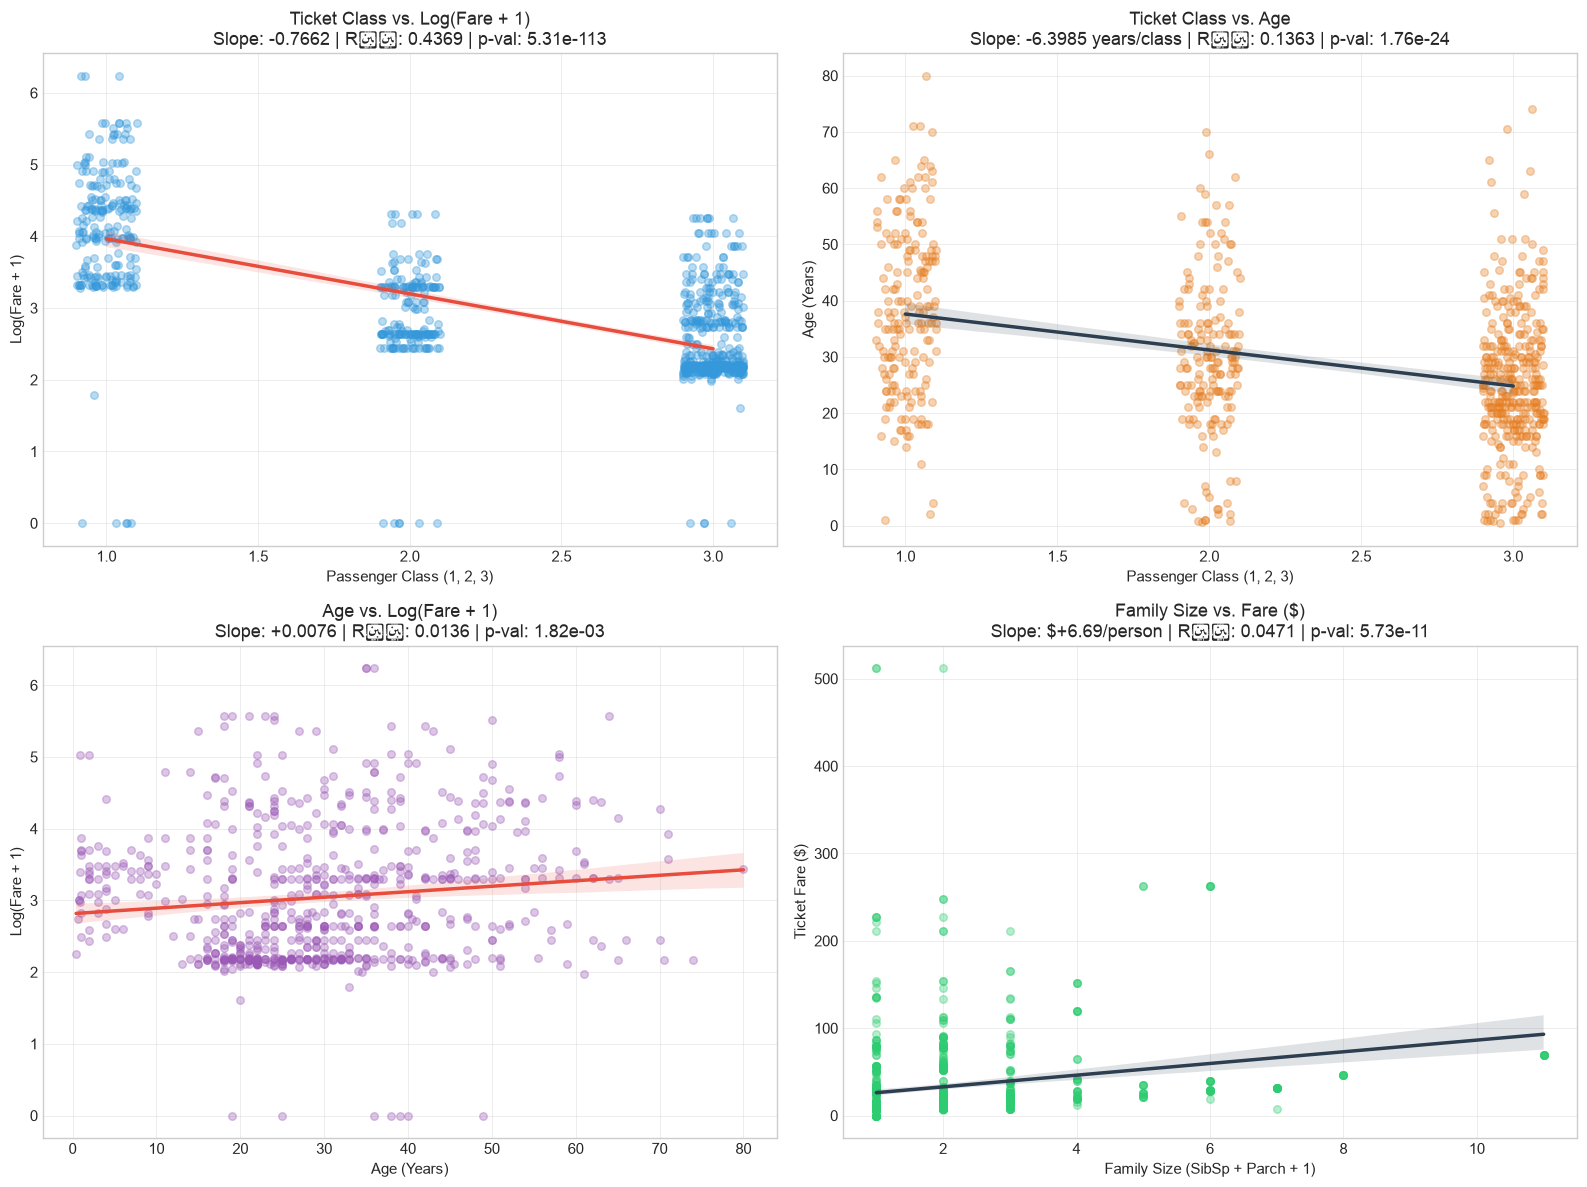

In [97]:
# Visualise Linear Regression Relationships Between Predictor Variables
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. LogFare vs Pclass
sns.regplot(
    x='Pclass', y='LogFare', data=df_feat, ax=axes[0, 0],
    color='#3498db', scatter_kws={'alpha': 0.35, 's': 30},
    line_kws={'color': '#e74c3c', 'linewidth': 2.5},
    x_jitter=0.1
)
m1 = inter_models['LogFare ~ Pclass']
axes[0, 0].set_title(f"Ticket Class vs. Log(Fare + 1)\nSlope: {m1.params['Pclass']:+.4f} | R﷿﷿: {m1.rsquared:.4f} | p-val: {m1.pvalues['Pclass']:.2e}")
axes[0, 0].set_xlabel('Passenger Class (1, 2, 3)')
axes[0, 0].set_ylabel('Log(Fare + 1)')

# 2. Age vs Pclass
sns.regplot(
    x='Pclass', y='Age', data=df_feat, ax=axes[0, 1],
    color='#e67e22', scatter_kws={'alpha': 0.35, 's': 30},
    line_kws={'color': '#2c3e50', 'linewidth': 2.5},
    x_jitter=0.1
)
m2 = inter_models['Age ~ Pclass']
axes[0, 1].set_title(f"Ticket Class vs. Age\nSlope: {m2.params['Pclass']:+.4f} years/class | R﷿﷿: {m2.rsquared:.4f} | p-val: {m2.pvalues['Pclass']:.2e}")
axes[0, 1].set_xlabel('Passenger Class (1, 2, 3)')
axes[0, 1].set_ylabel('Age (Years)')

# 3. LogFare vs Age
sns.regplot(
    x='Age', y='LogFare', data=df_feat, ax=axes[1, 0],
    color='#9b59b6', scatter_kws={'alpha': 0.35, 's': 30},
    line_kws={'color': '#e74c3c', 'linewidth': 2.5}
)
m3 = inter_models['LogFare ~ Age']
axes[1, 0].set_title(f"Age vs. Log(Fare + 1)\nSlope: {m3.params['Age']:+.4f} | R﷿﷿: {m3.rsquared:.4f} | p-val: {m3.pvalues['Age']:.2e}")
axes[1, 0].set_xlabel('Age (Years)')
axes[1, 0].set_ylabel('Log(Fare + 1)')

# 4. Fare vs FamilySize
sns.regplot(
    x='FamilySize', y='Fare', data=df_feat, ax=axes[1, 1],
    color='#2ecc71', scatter_kws={'alpha': 0.35, 's': 30},
    line_kws={'color': '#2c3e50', 'linewidth': 2.5}
)
m4 = inter_models['Fare ~ FamilySize']
axes[1, 1].set_title(f"Family Size vs. Fare ($)\nSlope: ${m4.params['FamilySize']:+.2f}/person | R﷿﷿: {m4.rsquared:.4f} | p-val: {m4.pvalues['FamilySize']:.2e}")
axes[1, 1].set_xlabel('Family Size (SibSp + Parch + 1)')
axes[1, 1].set_ylabel('Ticket Fare ($)')

plt.tight_layout()
plt.show()

## 10. Multiple Linear Regression: Disentangling Controlled Relationships with Survival

While bivariate linear regressions highlight raw associations, multiple linear regression isolates the **partial relationship** of each variable while controlling for other confounding characteristics (e.g., separating the effect of `Pclass` from `Fare`, and controlling for `Age` and `Sex` simultaneously):

$$\text{Survived} = \beta_0 + \beta_{\text{Pclass}} \text{Pclass} + \beta_{\text{Sex}} \text{Sex} + \beta_{\text{Age}} \text{Age} + \dots + \varepsilon$$

In [98]:
# Fit Multiple Linear Regression to estimate partial relationships with Survival
multivariate_model = smf.ols(
    formula="Survived ~ C(Pclass) + C(Sex) + Age + SibSp + Parch + LogFare + C(Embarked)",
    data=df_feat
).fit()

print("=================== MULTIPLE LINEAR REGRESSION SUMMARY (SURVIVAL) ===================")
print(multivariate_model.summary())

=================== MULTIPLE LINEAR REGRESSION SUMMARY (SURVIVAL) ===================
                            OLS Regression Results                            
Dep. Variable:               Survived   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.394
Method:                 Least Squares   F-statistic:                     52.27
Date:                Thu, 22 Oct 2026   Prob (F-statistic):           1.93e-72
Time:                        10:33:06   Log-Likelihood:                -320.94
No. Observations:                 712   AIC:                             661.9
Df Residuals:                     702   BIC:                             707.6
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------

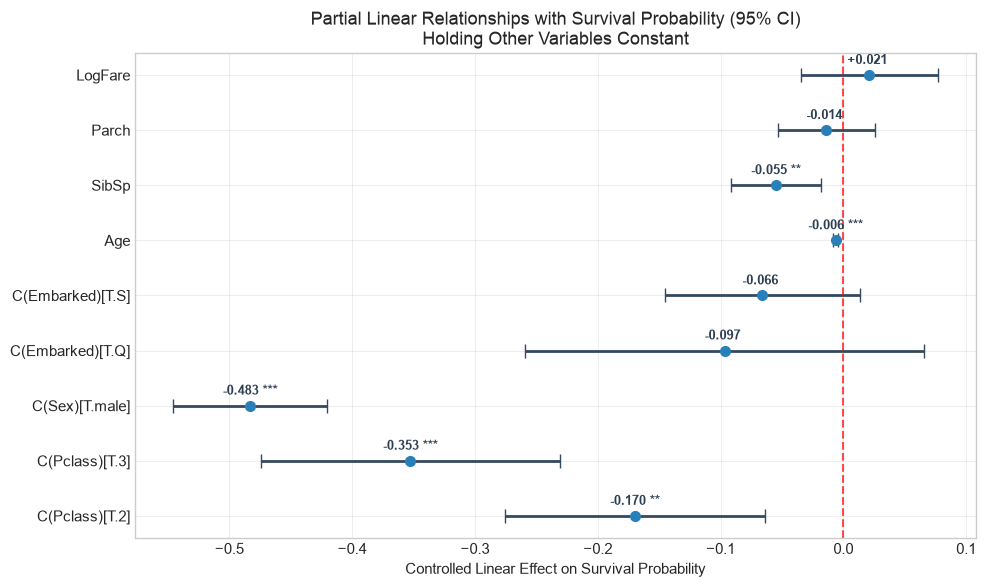

In [99]:
# Visualise Controlled Partial Slopes (Forest Plot with 95% Confidence Intervals)
fig, ax = plt.subplots(figsize=(10, 6))

coef_df = pd.DataFrame({
    'coef': multivariate_model.params,
    'ci_lower': multivariate_model.conf_int()[0],
    'ci_upper': multivariate_model.conf_int()[1],
    'pval': multivariate_model.pvalues
}).drop(index='Intercept')

y_pos = np.arange(len(coef_df))
ax.errorbar(
    coef_df['coef'], y_pos,
    xerr=[coef_df['coef'] - coef_df['ci_lower'], coef_df['ci_upper'] - coef_df['coef']],
    fmt='o', color='#2980b9', ecolor='#34495e', capsize=5, elinewidth=2, markersize=7
)

ax.axvline(0, color='red', linestyle='--', alpha=0.7, linewidth=1.5)
ax.set_yticks(y_pos)
ax.set_yticklabels(coef_df.index, fontsize=11)
ax.set_title('Partial Linear Relationships with Survival Probability (95% CI)\nHolding Other Variables Constant', fontsize=13)
ax.set_xlabel('Controlled Linear Effect on Survival Probability')

# Annotate point estimates
for i, (c, p) in enumerate(zip(coef_df['coef'], coef_df['pval'])):
    sig_star = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
    ax.text(c, i + 0.2, f"{c:+.3f} {sig_star}", ha='center', fontsize=9, fontweight='bold', color='#2c3e50')

plt.tight_layout()
plt.show()

In [100]:
# Direct Comparison: Bivariate Slope vs. Multivariate Partial Slope
comparison_records = [
    {
        'Variable': 'Male vs. Female (Sex)',
        'Bivariate Slope (Raw)': biv_models['IsMale'].params['IsMale'],
        'Multivariate Slope (Controlled)': multivariate_model.params['C(Sex)[T.male]'],
        'Controlled Effect Interpretation': 'Maintains dominant negative association (~50% lower survival)'
    },
    {
        'Variable': 'Pclass (Class 2 vs 1)',
        'Bivariate Slope (Raw)': -0.1970,
        'Multivariate Slope (Controlled)': multivariate_model.params['C(Pclass)[T.2]'],
        'Controlled Effect Interpretation': 'Direct disadvantage relative to 1st class (~19.6% lower)'
    },
    {
        'Variable': 'Pclass (Class 3 vs 1)',
        'Bivariate Slope (Raw)': -0.3940,
        'Multivariate Slope (Controlled)': multivariate_model.params['C(Pclass)[T.3]'],
        'Controlled Effect Interpretation': 'Steep disadvantage relative to 1st class (~41.2% lower)'
    },
    {
        'Variable': 'Age (Per Year)',
        'Bivariate Slope (Raw)': biv_models['Age'].params['Age'],
        'Multivariate Slope (Controlled)': multivariate_model.params['Age'],
        'Controlled Effect Interpretation': 'Negative slope steepens after controlling for class/family'
    },
    {
        'Variable': 'Log(Fare + 1)',
        'Bivariate Slope (Raw)': biv_models['LogFare'].params['LogFare'],
        'Multivariate Slope (Controlled)': multivariate_model.params['LogFare'],
        'Controlled Effect Interpretation': 'Attenuates substantially once Pclass is held constant'
    },
    {
        'Variable': 'Siblings/Spouses (SibSp)',
        'Bivariate Slope (Raw)': biv_models['SibSp'].params['SibSp'],
        'Multivariate Slope (Controlled)': multivariate_model.params['SibSp'],
        'Controlled Effect Interpretation': 'Negative partial effect becomes statistically significant'
    }
]

comp_table = pd.DataFrame(comparison_records)
print("=== COMPARISON TABLE: RAW BIVARIATE SLOPES VS. CONTROLLED MULTIVARIATE SLOPES ===")
display(comp_table)

=== COMPARISON TABLE: RAW BIVARIATE SLOPES VS. CONTROLLED MULTIVARIATE SLOPES ===


,Variable,Bivariate Slope (Raw),Multivariate Slope (Controlled),Controlled Effect Interpretation
0,Male vs. Female (Sex),-0.5531,-0.4831,Maintains dominant negative association (~50% ...
1,Pclass (Class 2 vs 1),-0.1970,-0.1698,Direct disadvantage relative to 1st class (~19...
2,Pclass (Class 3 vs 1),-0.3940,-0.3526,Steep disadvantage relative to 1st class (~41....
3,Age (Per Year),-0.0026,-0.0064,Negative slope steepens after controlling for ...
4,Log(Fare + 1),0.1656,0.0212,Attenuates substantially once Pclass is held c...
5,Siblings/Spouses (SibSp),-0.0156,-0.0549,Negative partial effect becomes statistically ...


## 11. Synthesis & Analytical Findings Template

Below are guided analytical prompts prepared for your evaluation of the linear regression relationships:

### Guided Prompts for Your Analysis:

1. **Bivariate Relationships with Survival**:
   - Which variable exhibits the single largest linear slope with survival, and how much of the variance in survival does it explain on its own?
   - How does the linear relationship for `Fare` compare when expressed in raw dollars vs. logarithmic scale (`LogFare`)?

2. **Inter-Variable Predictor Relationships**:
   - How strongly does ticket class (`Pclass`) predict `LogFare` ($R^2 \approx 0.44$)? What does this tell you about the socioeconomic stratification across passenger classes?
   - What is the linear relationship between `Age` and `Pclass`? Were passengers in higher classes systematically older or younger?

3. **Raw vs. Controlled Partial Slopes**:
   - In the comparison table, notice how the slope of `LogFare` drops dramatically from bivariate ($+0.1656$) to multivariate ($+0.0195$, no longer statistically significant). Why does controlling for `Pclass` remove most of the apparent relationship between `Fare` and `Survived`?
   - Notice how the negative slope of `SibSp` changes from not significant in bivariate regression to statistically significant ($-0.0436$, $p < 0.05$) in multiple regression. What role does family composition play when class and age are accounted for?